# Single-Cell Position Tuning Analysis (2p)

Organizes each cell's responses by stimulus position, visualizes individual trial traces,
and computes mean tuning curves.

In [2]:
import sys
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
sys.path.append(base_dir)
sys.path.append(base_dir + r"\radial-analysis")  # so src.ActivityPipelines resolves
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy import io
from src.ActivityPipelines import ActivityLoader
from src.utils import import_vars_from_matlab, create_new_result_dir
import os

In [9]:
# ── Configuration ───────────────────────────────────────────────────────────
record_date     = '260311'
mouse_name      = 'SAM041'
experiment_name = 'goggles_right'    # 'goggles_right' | 'goggles_left'

data_dir = (
    r'D:/data-distance-coding-project/processed-data/'
    f'{record_date}_{mouse_name}_{experiment_name}/'
)

# Stimulus .mat file
stim_filename = (
    data_dir + f'stimulus/{record_date}_{mouse_name}_{experiment_name}_stim.mat'
)
stim_matlab_var = 'stim'

if not os.path.exists(data_dir):
    raise FileNotFoundError(f"Data directory not found: {data_dir}")
print(f"Data directory: {data_dir}")
print(f"Stimulus file : {stim_filename}")

Data directory: D:/data-distance-coding-project/processed-data/260311_SAM041_goggles_right/
Stimulus file : D:/data-distance-coding-project/processed-data/260311_SAM041_goggles_right/stimulus/260311_SAM041_goggles_right_stim.mat


## 1 — Load activity data

In [10]:
D = ActivityLoader(data_dir)

n_cells  = D.dFF.shape[0]
n_frames = D.dFF.shape[1]
print(f"Cells: {n_cells}  |  Frames: {n_frames}")
print(f"frames_time range: {D.frames_time[0]:.1f} – {D.frames_time[-1]:.1f} ms")

Cells: 978  |  Frames: 6014
frames_time range: 0.0 – 599985.8 ms


## 2 — Load stimulus data

In [11]:
stim_mat   = io.loadmat(stim_filename)
stim       = stim_mat[stim_matlab_var]

positions     = stim['positions'][0, 0].flatten()          # (n_positions,) degrees
position_order = stim['position_order'][0, 0]              # (n_repeats, n_pos_per_rep) 1-indexed
stim_on       = stim['stim_on'][0, 0]                      # (n_repeats, n_pos_per_rep) seconds
stim_end      = stim['stim_end'][0, 0]                     # (n_repeats, n_pos_per_rep) seconds

n_repeats, n_pos_per_rep = position_order.shape
n_positions = len(positions)

print(f"Positions ({n_positions}): {np.round(positions, 1)}")
print(f"Repeats: {n_repeats}  |  Trials per repeat: {n_pos_per_rep}")
print(f"Trial duration: {(stim_end[0,0] - stim_on[0,0]):.2f} s")

Positions (10): [  0.   13.3  26.7  40.   53.3  66.7  80.   93.3 106.7 120. ]
Repeats: 10  |  Trials per repeat: 10
Trial duration: 2.00 s


## 3 — Extract per-position traces for every cell

In [12]:
def get_position_traces(cell_idx):
    """
    For one cell (row index into D.dFF), return a list of n_positions arrays.
    Each element is an ndarray of shape (n_trials_for_pos, on_length),
    where on_length = shortest on-window across all trials.

    Parameters
    ----------
    cell_idx : int
        Row index in D.dFF (not suite2p ID).

    Returns
    -------
    traces_by_pos : list of ndarray, length n_positions
    on_length     : int — number of frames in the on window
    """
    raw = {p: [] for p in range(n_positions)}

    for rep in range(n_repeats):
        for trial in range(n_pos_per_rep):
            pos_idx     = int(position_order[rep, trial]) - 1          # 0-indexed
            on_start_ms = stim_on[rep, trial]  * 1000.0
            on_end_ms   = stim_end[rep, trial] * 1000.0
            on_frames   = (D.frames_time > on_start_ms) & (D.frames_time < on_end_ms)
            trace       = D.dFF[cell_idx, on_frames]
            raw[pos_idx].append(trace)

    # Clip all traces to shortest length
    on_length = min(len(t) for pos_traces in raw.values() for t in pos_traces)
    traces_by_pos = [np.vstack([t[:on_length] for t in raw[p]]) for p in range(n_positions)]
    return traces_by_pos, on_length


# Quick sanity check on cell 0
traces_test, on_length = get_position_traces(0)
print(f"on_length = {on_length} frames")
print(f"Trials per position: {[t.shape[0] for t in traces_test]}")

on_length = 20 frames
Trials per position: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


## 4 — Single-cell plot: individual traces + tuning curve

In [13]:
def plot_single_cell(cell_idx, fig=None):
    """
    Two-panel figure for one cell:
      Left  — individual trial traces for each position (colour-coded)
      Right — mean ± SEM tuning curve (mean dF/F within on-window vs. position)

    Parameters
    ----------
    cell_idx : int  (row index into D.dFF)
    """
    traces_by_pos, on_len = get_position_traces(cell_idx)
    cell_id = D.suite2p_id[cell_idx]

    cmap   = cm.get_cmap('viridis', n_positions)
    colors = [cmap(i) for i in range(n_positions)]
    t_axis = np.arange(on_len)          # frame indices within on-window

    if fig is None:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    else:
        axes = fig.subplots(1, 2)

    # ── Panel 1: individual traces ─────────────────────────────────────────
    ax = axes[0]
    for p_idx, (traces, color, pos_val) in enumerate(
        zip(traces_by_pos, colors, positions)
    ):
        for trace in traces:
            ax.plot(t_axis, trace, color=color, alpha=0.25, linewidth=0.8)
        mean_t = traces.mean(axis=0)
        ax.plot(t_axis, mean_t, color=color, linewidth=2,
                label=f'{pos_val:.1f}°')

    ax.set_xlabel('Frame (within on-window)')
    ax.set_ylabel('dF/F')
    ax.set_title(f'Cell {cell_id} — Individual Trials')
    ax.legend(title='Position', fontsize=7, ncol=2, loc='upper right')

    # ── Panel 2: tuning curve ──────────────────────────────────────────────
    ax2 = axes[1]
    means = np.array([traces.mean() for traces in traces_by_pos])
    sems  = np.array([
        traces.mean(axis=1).std() / np.sqrt(traces.shape[0])
        for traces in traces_by_pos
    ])

    ax2.plot(positions, means, 'o-', color='black', linewidth=2, markersize=5)
    ax2.fill_between(positions, means - sems, means + sems,
                     color='black', alpha=0.2)

    peak_pos = positions[np.argmax(means)]
    ax2.axvline(peak_pos, color='red', linestyle='--', linewidth=1.2,
                label=f'Peak: {peak_pos:.1f}°')
    ax2.legend()
    ax2.set_xlabel('Position (°)')
    ax2.set_ylabel('Mean dF/F ± SEM')
    ax2.set_title(f'Cell {cell_id} — Tuning Curve')

    plt.tight_layout()
    return fig

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_769312\2674677291.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap('viridis', n_positions)


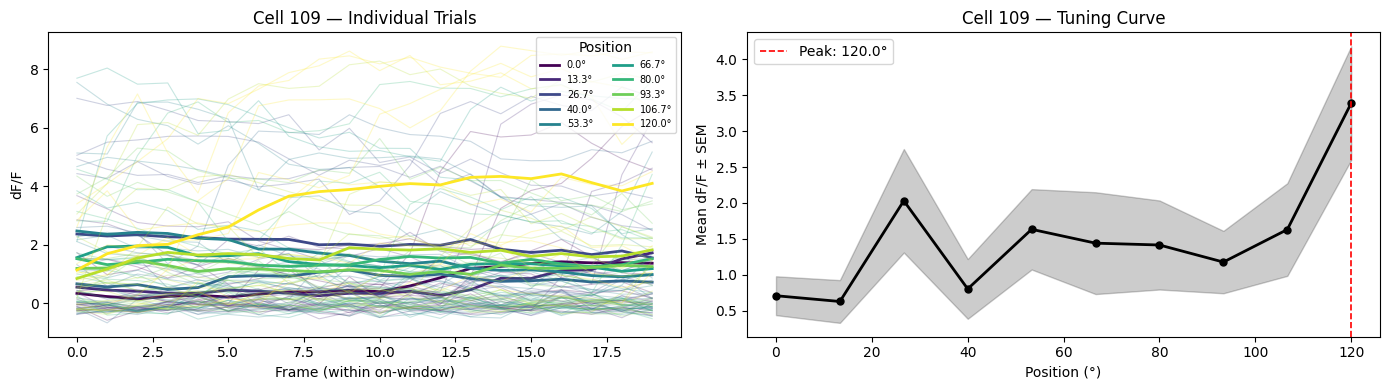

In [22]:
# Example: plot cell with suite2p ID 0  (change to any ID you want)
cell_to_show = 109   # suite2p ID
cell_idx = np.where(D.suite2p_id == cell_to_show)[0][0]
fig = plot_single_cell(cell_idx)
plt.show()

## 5 — Multi-cell tuning curve grid

In [ ]:
def plot_tuning_grid(cell_indices=None, ncols=5, normalize=True):
    """
    Grid of mean tuning curves for multiple cells.

    Parameters
    ----------
    cell_indices : array-like of int, optional
        Row indices into D.dFF.  Defaults to all cells.
    ncols : int
        Number of columns in the grid.
    normalize : bool
        If True, normalise each curve to its peak (0–1 range).
    """
    if cell_indices is None:
        cell_indices = np.arange(n_cells)

    n = len(cell_indices)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 2.5, nrows * 2),
                             sharey=False)
    axes = np.array(axes).reshape(-1)

    for ax_i, cell_idx in enumerate(cell_indices):
        traces_by_pos, _ = get_position_traces(cell_idx)
        means = np.array([traces.mean() for traces in traces_by_pos])
        sems  = np.array([
            traces.mean(axis=1).std() / np.sqrt(traces.shape[0])
            for traces in traces_by_pos
        ])

        if normalize and means.max() != means.min():
            scale = means.max() - means.min()
            means_plot = (means - means.min()) / scale
            sems_plot  = sems / scale
        else:
            means_plot, sems_plot = means, sems

        ax = axes[ax_i]
        ax.plot(positions, means_plot, 'o-', color='steelblue',
                linewidth=1.5, markersize=3)
        ax.fill_between(positions,
                        means_plot - sems_plot,
                        means_plot + sems_plot,
                        color='steelblue', alpha=0.25)
        ax.set_title(f'Cell {D.suite2p_id[cell_idx]}', fontsize=8)
        ax.set_xticks(positions[::3])
        ax.tick_params(labelsize=6)

    # Hide unused axes
    for ax in axes[n:]:
        ax.set_visible(False)

    fig.supxlabel('Position (°)', fontsize=10)
    fig.supylabel('dF/F (normalised)' if normalize else 'dF/F', fontsize=10)
    plt.tight_layout()
    return fig

In [ ]:
# Plot all cells (adjust ncols to taste)
fig = plot_tuning_grid(ncols=5)
plt.show()

## 6 — Save figures for all cells

In [ ]:
fig_path = create_new_result_dir(data_dir, 'position_tuning')
print(f"Saving figures to: {fig_path}")

for cell_idx in range(n_cells):
    fig = plot_single_cell(cell_idx)
    cell_id = D.suite2p_id[cell_idx]
    fig.savefig(os.path.join(fig_path, f'cell_{cell_id}.png'), dpi=150)
    plt.close(fig)

print("Done.")